In [3]:
%pip install ucimlrepo

Number of samples: 398
First five vehicle weights: [3504. 3693. 3436. 3433. 3449.]
First five MPG values: [18. 15. 18. 16. 17.]


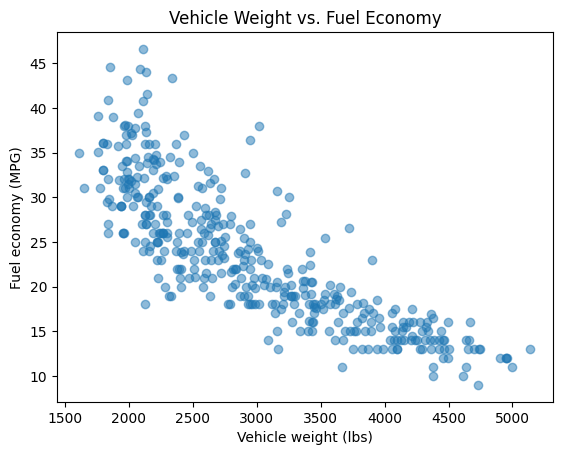

In [15]:
from ucimlrepo import fetch_ucirepo
import matplotlib.pyplot as plt

# Fetch real-world data from UCI
cars = fetch_ucirepo(id=9)

# Convert the selected columns to NumPy arrays
x = cars.data.features["weight"].to_numpy(dtype=float)
y = cars.data.targets["mpg"].to_numpy(dtype=float)

print("Number of samples:", x.shape[0])
print("First five vehicle weights:", x[:5])
print("First five MPG values:", y[:5])

plt.scatter(x, y, alpha=0.5)
plt.xlabel("Vehicle weight (lbs)")
plt.ylabel("Fuel economy (MPG)")
plt.title("Vehicle Weight vs. Fuel Economy")
plt.show()

In [16]:
#compute J(w, b)
def compute_cost(x, y, w, b):
  cost = 0;
  m = x.shape[0]
  for i in range(m):
    error = w*x[i] + b - y[i]
    cost += error ** 2
  cost /= 2*m
  return cost


In [17]:
#Gradient Descent
def gradient_descent(w, b, alpha, x, y):
  dj_dw = 0
  dj_db = 0
  m = x.shape[0]
  for i in range(m):
    error = w*x[i] + b - y[i]
    dj_dw += x[i] * error
    dj_db += error
  dj_dw /= m
  dj_db /= m
  w -= alpha * dj_dw
  b -= alpha * dj_db
  return w, b

In [21]:
iteration = 10000
alpha = 0.01
w = 0
b = 0
x_train = x/1000

for i in range(iteration):
  w, b = gradient_descent(w, b, alpha, x_train, y)

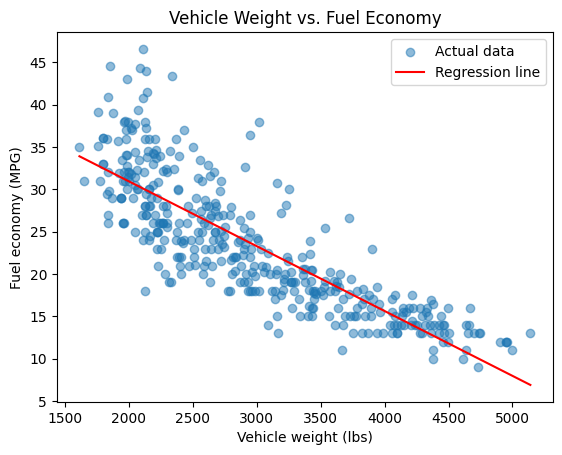

In [22]:
#plot
import numpy as np
import matplotlib.pyplot as plt


x_line = np.array([x.min(), x.max()])
y_line = w * (x_line/1000) + b

plt.scatter(x, y, alpha=0.5, label="Actual data")
plt.plot(x_line, y_line, color="red", label="Regression line")

plt.xlabel("Vehicle weight (lbs)")
plt.ylabel("Fuel economy (MPG)")
plt.title("Vehicle Weight vs. Fuel Economy")
plt.legend()
plt.show()